In [1]:
import numpy as nd 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('/kaggle/input/datasets/redwankarimsony/heart-disease-data/heart_disease_uci.csv')

In [2]:
df.shape

(920, 16)

In [3]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [5]:
df.describe(include = "all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


In [6]:
df.columns

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')

In [7]:
df["sex"].unique()


array(['Male', 'Female'], dtype=object)

In [8]:
df["cp"].unique()
df["num"].unique()

array([0, 2, 1, 3, 4])

In [9]:
df["num"].value_counts().sort_index()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

In [10]:
(df["num"] > 0).value_counts()

num
True     509
False    411
Name: count, dtype: int64

In [11]:
(df["num"] > 0).value_counts(normalize=True) * 100

num
True     55.326087
False    44.673913
Name: proportion, dtype: float64

In [12]:
df.isna().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [13]:
miss = df.isna().sum().to_frame("n")
miss["pct"] = miss["n"] / len(df) *100
miss.sort_values("pct",ascending=False)

,n,pct
ca,611,66.413043
thal,486,52.826087
slope,309,33.586957
fbs,90,9.782609
oldpeak,62,6.739130
trestbps,59,6.413043
exang,55,5.978261
thalch,55,5.978261
chol,30,3.260870
restecg,2,0.217391


In [14]:
print((df["chol"] == 0).sum())
print((df["trestbps"] == 0).sum())
print((df["oldpeak"] < 0).sum())

172
1
12


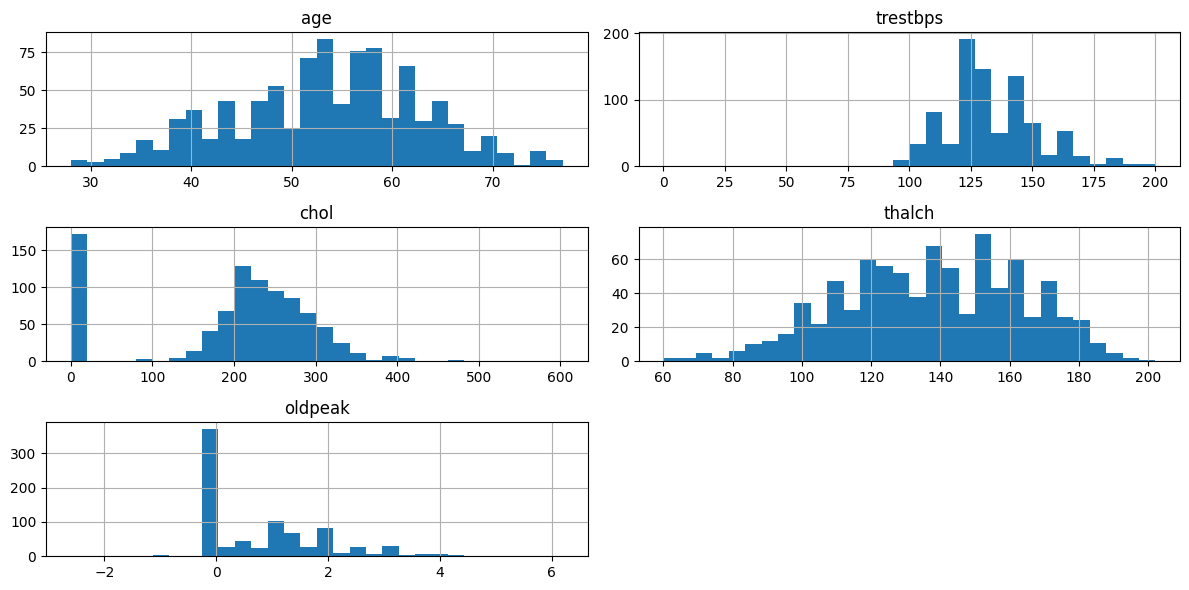

In [15]:
num_cols = ["age" ,"trestbps","chol","thalch","oldpeak"]
df[num_cols].hist(bins=30,figsize=(12,6))
plt.tight_layout()
plt.show()

In [16]:
df["target"] = (df["num"] > 0).astype(int)

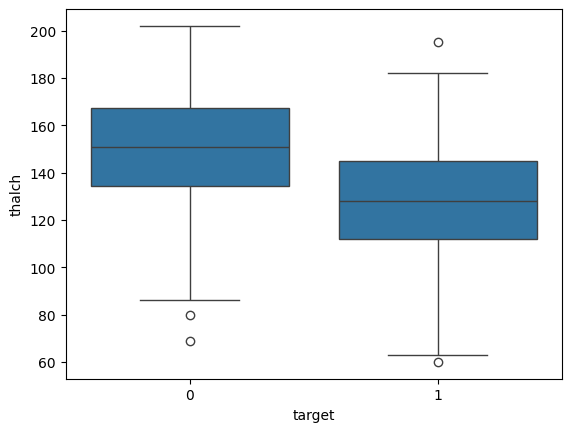

In [17]:
sns.boxplot(data=df,x="target",y="thalch")
plt.show()

In [18]:
df.groupby("dataset")["target"].mean()

dataset
Cleveland        0.457237
Hungary          0.361775
Switzerland      0.934959
VA Long Beach    0.745000
Name: target, dtype: float64

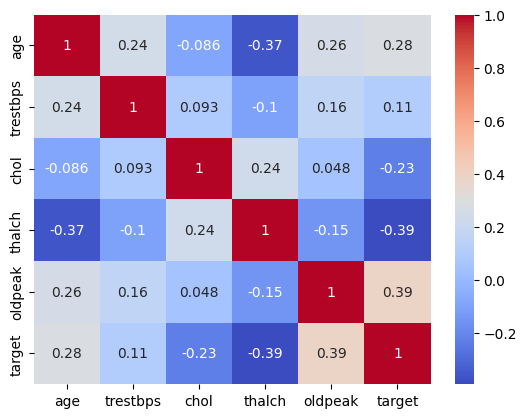

In [19]:
sns.heatmap(
    df[num_cols + ["target"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.show()

## Cleaning the data

In [20]:
df_clean = df.copy()

In [21]:
print(df_clean.columns)

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num',
       'target'],
      dtype='object')


In [22]:
df_clean = df_clean.drop(columns=["id"], errors="ignore")

In [23]:
import numpy as np

In [24]:
df_clean.loc[df_clean["chol"] == 0, "chol"] = np.nan

df_clean.loc[df_clean["trestbps"] == 0, "trestbps"] = np.nan

In [25]:
print("Cholesterol zeros:", (df_clean["chol"] == 0).sum())
print("Blood pressure zeros:", (df_clean["trestbps"] == 0).sum())

Cholesterol zeros: 0
Blood pressure zeros: 0


In [26]:
missing = df_clean.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

ca          611
thal        486
slope       309
chol        202
fbs          90
oldpeak      62
trestbps     60
thalch       55
exang        55
restecg       2
dtype: int64


In [27]:
df_clean.duplicated().sum()

np.int64(2)

In [28]:
df_clean[df_clean.duplicated()]

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
405,49,Female,Hungary,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0,0
907,58,Male,VA Long Beach,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,NaN,NaN,NaN,2,1


In [29]:
df_clean = df_clean.drop_duplicates()

In [30]:
df_clean.duplicated().sum()

np.int64(0)

In [31]:
df_clean["target"] = (df_clean["num"] > 0).astype(int)

In [32]:
print(df_clean[["num", "target"]].head(10))

   num  target
0    0       0
1    2       1
2    1       1
3    0       0
4    0       0
5    0       0
6    3       1
7    0       0
8    2       1
9    1       1


In [33]:
X = df_clean.drop(columns=["num", "target"])
y = df_clean["target"]

In [34]:
print(X.shape)
print(y.shape)
print(X.columns.tolist())

(918, 14)
(918,)
['age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [35]:
RANDOM_STATE = 42

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

In [37]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training data: (734, 14)
Testing data: (184, 14)
Training targets: (734,)
Testing targets: (184,)


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [39]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)

Numeric columns: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Categorical columns: ['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [40]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [41]:
pre_scaled = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

In [42]:
Xt = pre_scaled.fit_transform(X_train)

print("Processed shape:", Xt.shape)
print("Missing values:", np.isnan(Xt).sum())

Processed shape: (734, 29)
Missing values: 0


In [43]:
X_test_processed = pre_scaled.transform(X_test)

print("Train shape:", Xt.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (734, 29)
Test shape: (184, 29)


# Logistic Regression model to predict

In [44]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(Xt, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [45]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)

              precision    recall  f1-score   support

           0       0.90      0.77      0.83        82
           1       0.83      0.93      0.88       102

    accuracy                           0.86       184
   macro avg       0.87      0.85      0.85       184
weighted avg       0.86      0.86      0.86       184

ROC-AUC: 0.9331659493065518


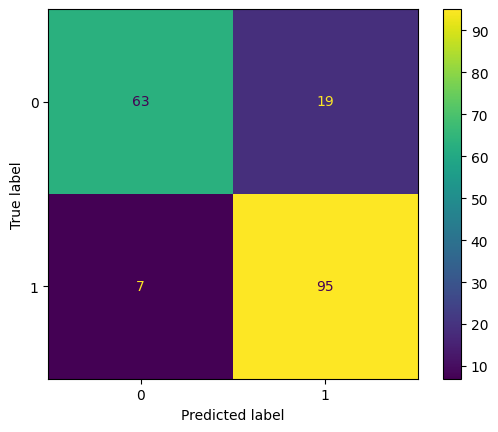

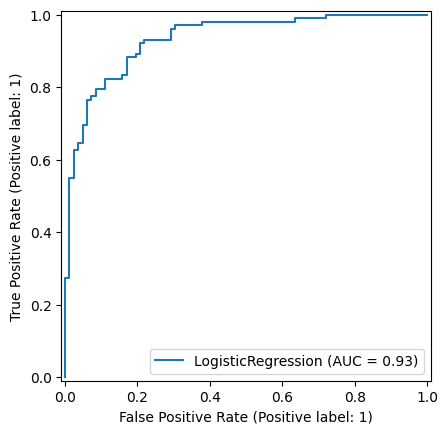

In [46]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score

y_pred = model.predict(X_test_processed)

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, model.predict_proba(X_test_processed)[:, 1]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
RocCurveDisplay.from_estimator(model, X_test_processed, y_test)

In [47]:
print("Training accuracy:", model.score(Xt, y_train))
print("Test accuracy:", model.score(X_test_processed, y_test))

Training accuracy: 0.832425068119891
Test accuracy: 0.8586956521739131


In [48]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model, Xt, y_train,
    cv=5,
    scoring="roc_auc"
)

print("ROC-AUC scores:", scores)
print("Average ROC-AUC:", scores.mean())

ROC-AUC scores: [0.9217636  0.88458661 0.88832772 0.90048634 0.88983856]
Average ROC-AUC: 0.8970005664314608


In [49]:
feature_names = pre_scaled.get_feature_names_out()
coefficients = model.coef_[0]

for feature, coef in zip(feature_names, coefficients):
    print(feature, ":", round(coef, 3))

num__age : 0.16
num__trestbps : 0.051
num__chol : 0.252
num__thalch : -0.197
num__oldpeak : 0.534
num__ca : 0.636
cat__sex_Female : -0.55
cat__sex_Male : 0.608
cat__dataset_Cleveland : -1.02
cat__dataset_Hungary : -0.697
cat__dataset_Switzerland : 1.738
cat__dataset_VA Long Beach : 0.037
cat__cp_asymptomatic : 0.975
cat__cp_atypical angina : -0.775
cat__cp_non-anginal : -0.13
cat__cp_typical angina : -0.012
cat__fbs_False : -0.049
cat__fbs_True : 0.106
cat__restecg_lv hypertrophy : 0.079
cat__restecg_normal : -0.104
cat__restecg_st-t abnormality : 0.082
cat__exang_False : -0.497
cat__exang_True : 0.554
cat__slope_downsloping : -0.318
cat__slope_flat : 0.592
cat__slope_upsloping : -0.217
cat__thal_fixed defect : 0.083
cat__thal_normal : -0.412
cat__thal_reversable defect : 0.386


In [50]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(
        y_test, model.predict_proba(X_test_processed)[:, 1]
    )
}])

results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.858696,0.833333,0.931373,0.87963,0.933166


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

num_tree_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_tree_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

pre_tree = ColumnTransformer([
    ("num", num_tree_pipe, num_cols),
    ("cat", cat_tree_pipe, cat_cols)
])

print("Tree preprocessing pipeline created.")

Tree preprocessing pipeline created.


In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf = Pipeline([
    ("pre", pre_tree),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE
    ))
])

rf.fit(X_train, y_train)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalch', 'oldpeak', 'ca']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'dataset', 'cp',
                                                   'fbs', 'restecg', 'exang',
                                                   'slope', 'thal'])])),
                ('clf',
                 RandomForestClassifier(n_estimators=300, random_state=42))])

              precision    recall  f1-score   support

           0       0.81      0.79      0.80        82
           1       0.84      0.85      0.84       102

    accuracy                           0.83       184
   macro avg       0.82      0.82      0.82       184
weighted avg       0.83      0.83      0.83       184

ROC-AUC: 0.9220468675274989


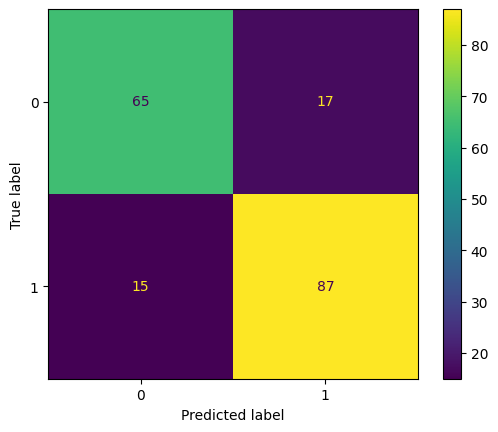

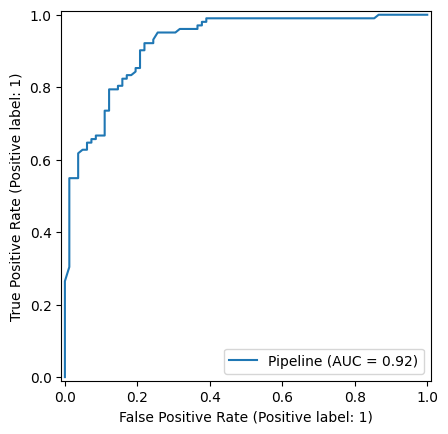

In [53]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)

rf_pred = rf.predict(X_test)

print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test)
RocCurveDisplay.from_estimator(rf, X_test, y_test)

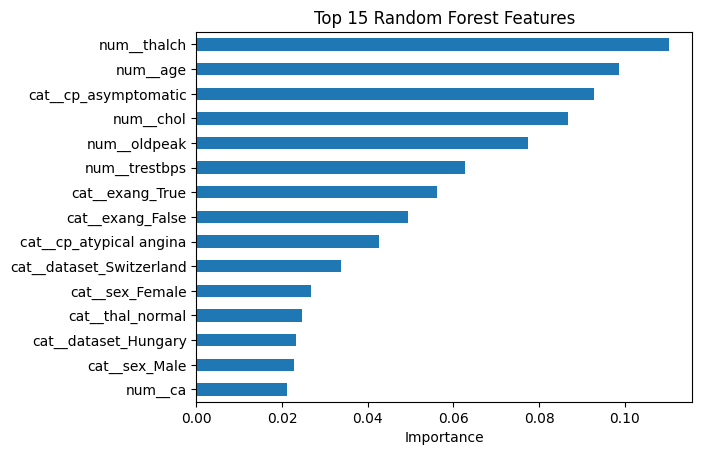

In [54]:
imp = pd.Series(
    rf["clf"].feature_importances_,
    index=rf["pre"].get_feature_names_out()
)

imp.nlargest(15).sort_values().plot.barh()
plt.title("Top 15 Random Forest Features")
plt.xlabel("Importance")
plt.show()

In [55]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb = Pipeline([
    ("pre", pre_tree),
    ("clf", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        eval_metric="logloss",
        random_state=RANDOM_STATE
    ))
])

xgb.fit(X_train, y_train)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalch', 'oldpeak', 'ca']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'dataset', 'cp',
                                                   'fbs', 'restecg', 'exang',...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

              precision    recall  f1-score   support

           0       0.85      0.76      0.80        82
           1       0.82      0.89      0.85       102

    accuracy                           0.83       184
   macro avg       0.83      0.82      0.83       184
weighted avg       0.83      0.83      0.83       184

ROC-AUC: 0.9224055475848876


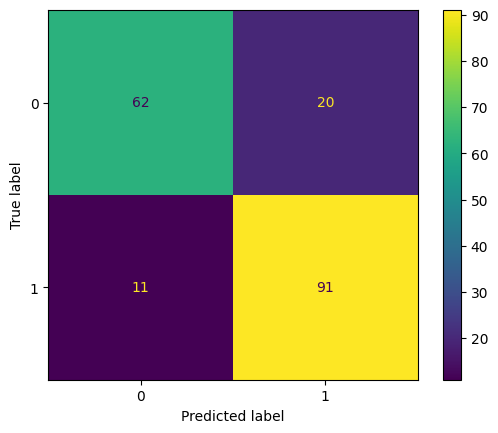

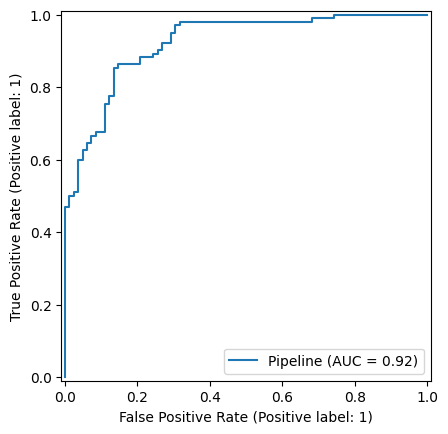

In [56]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)

xgb_pred = xgb.predict(X_test)

print(classification_report(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(
    y_test, xgb.predict_proba(X_test)[:, 1]
))

ConfusionMatrixDisplay.from_estimator(xgb, X_test, y_test)
RocCurveDisplay.from_estimator(xgb, X_test, y_test)

In [57]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    xgb, X_train, y_train,
    cv=5,
    scoring="roc_auc"
)

print("AUC scores:", scores)
print("Average AUC:", scores.mean())

AUC scores: [0.90412758 0.87560793 0.86363636 0.89057239 0.88129155]
Average AUC: 0.8830471626135582


In [58]:
for depth in [2, 3, 5]:
    test_xgb = Pipeline([
        ("pre", pre_tree),
        ("clf", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=depth,
            eval_metric="logloss",
            random_state=RANDOM_STATE
        ))
    ])

    scores = cross_val_score(
        test_xgb, X_train, y_train,
        cv=5, scoring="roc_auc"
    )

    print("Depth:", depth, "| Average AUC:", round(scores.mean(), 4))

Depth: 2 | Average AUC: 0.8922
Depth: 3 | Average AUC: 0.883
Depth: 5 | Average AUC: 0.873


In [59]:
for rate in [0.03, 0.1]:
    test_xgb = Pipeline([
        ("pre", pre_tree),
        ("clf", XGBClassifier(
            n_estimators=300,
            learning_rate=rate,
            max_depth=3,
            eval_metric="logloss",
            random_state=RANDOM_STATE
        ))
    ])

    scores = cross_val_score(
        test_xgb, X_train, y_train,
        cv=5, scoring="roc_auc"
    )

    print("Learning rate:", rate, "| Average AUC:", round(scores.mean(), 4))

Learning rate: 0.03 | Average AUC: 0.8887
Learning rate: 0.1 | Average AUC: 0.8798


In [60]:
for n in [100, 300]:
    test_xgb = Pipeline([
        ("pre", pre_tree),
        ("clf", XGBClassifier(
            n_estimators=n,
            learning_rate=0.05,
            max_depth=3,
            eval_metric="logloss",
            random_state=RANDOM_STATE
        ))
    ])

    scores = cross_val_score(
        test_xgb, X_train, y_train,
        cv=5, scoring="roc_auc"
    )

    print("Trees:", n, "| Average AUC:", round(scores.mean(), 4))

Trees: 100 | Average AUC: 0.8883
Trees: 300 | Average AUC: 0.883


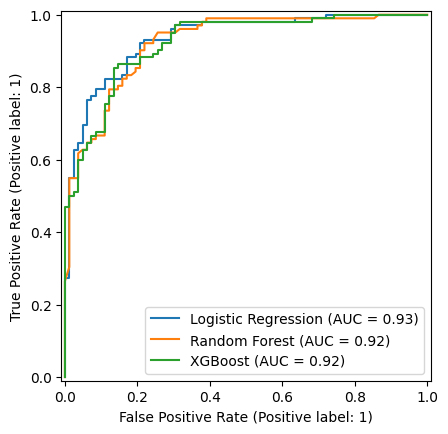

In [61]:
fig, ax = plt.subplots()

RocCurveDisplay.from_estimator(
    model, X_test_processed, y_test,
    name="Logistic Regression", ax=ax
)
RocCurveDisplay.from_estimator(
    rf, X_test, y_test,
    name="Random Forest", ax=ax
)
RocCurveDisplay.from_estimator(
    xgb, X_test, y_test,
    name="XGBoost", ax=ax
)

plt.show()

In [62]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(
            y_test, model.predict_proba(X_test_processed)[:, 1]
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf.predict(X_test)),
        "Precision": precision_score(y_test, rf.predict(X_test)),
        "Recall": recall_score(y_test, rf.predict(X_test)),
        "F1": f1_score(y_test, rf.predict(X_test)),
        "ROC-AUC": roc_auc_score(
            y_test, rf.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, xgb.predict(X_test)),
        "Precision": precision_score(y_test, xgb.predict(X_test)),
        "Recall": recall_score(y_test, xgb.predict(X_test)),
        "F1": f1_score(y_test, xgb.predict(X_test)),
        "ROC-AUC": roc_auc_score(
            y_test, xgb.predict_proba(X_test)[:, 1]
        )
    }
])

results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.859,0.833,0.931,0.880,0.933
1,Random Forest,0.826,0.837,0.853,0.845,0.922
2,XGBoost,0.832,0.820,0.892,0.854,0.922


In [63]:
X_train_no_ds = X_train.drop(columns=["dataset"])
X_test_no_ds = X_test.drop(columns=["dataset"])

cat_cols_no_ds = [c for c in cat_cols if c != "dataset"]

pre_tree_no_ds = ColumnTransformer([
    ("num", num_tree_pipe, num_cols),
    ("cat", cat_tree_pipe, cat_cols_no_ds)
])

rf_no_ds = Pipeline([
    ("pre", pre_tree_no_ds),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE
    ))
])

rf_no_ds.fit(X_train_no_ds, y_train)

print("ROC-AUC without dataset:",
      roc_auc_score(
          y_test,
          rf_no_ds.predict_proba(X_test_no_ds)[:, 1]
      ))

ROC-AUC without dataset: 0.8969392635102821


In [64]:
cat_cols_no_ds = [c for c in cat_cols if c != "dataset"]

pre_scaled_no_ds = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols_no_ds)
])

logreg_no_ds = Pipeline([
    ("pre", pre_scaled_no_ds),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logreg_no_ds.fit(X_train_no_ds, y_train)

print("ROC-AUC without dataset:",
      roc_auc_score(
          y_test,
          logreg_no_ds.predict_proba(X_test_no_ds)[:, 1]
      ))

ROC-AUC without dataset: 0.8946676231468197


In [65]:
xgb_no_ds = Pipeline([
    ("pre", pre_tree_no_ds),
    ("clf", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        eval_metric="logloss",
        random_state=RANDOM_STATE
    ))
])

xgb_no_ds.fit(X_train_no_ds, y_train)

print("ROC-AUC without dataset:",
      roc_auc_score(
          y_test,
          xgb_no_ds.predict_proba(X_test_no_ds)[:, 1]
      ))

ROC-AUC without dataset: 0.9037541846006696


In [66]:
y_multi = df_clean["num"]

print(y_multi.value_counts().sort_index())

num
0    410
1    265
2    108
3    107
4     28
Name: count, dtype: int64


In [67]:
from sklearn.model_selection import train_test_split

X_multi = df_clean.drop(columns=["num", "target"])
y_multi = df_clean["num"]

Xtr, Xte, ytr, yte = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    stratify=y_multi,
    random_state=RANDOM_STATE
)

print("Training shape:", Xtr.shape)
print("Testing shape:", Xte.shape)
print("Test class counts:")
print(yte.value_counts().sort_index())

Training shape: (734, 14)
Testing shape: (184, 14)
Test class counts:
num
0    82
1    53
2    22
3    21
4     6
Name: count, dtype: int64


In [68]:
logreg_multi = Pipeline([
    ("pre", pre_scaled),
    ("clf", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

logreg_multi.fit(Xtr, ytr)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalch', 'oldpeak', 'ca']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'dataset', 'cp',
                                                   'fbs', 'restecg', 'exang',
                                                   'slope', 'thal'])])),
                ('clf', LogisticRegression(max_iter=2000, random_state=42))])

In [69]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_multi_pred = logreg_multi.predict(Xte)

print("Macro F1-score:", f1_score(yte, y_multi_pred, average="macro"))
print("\nClassification Report:\n")
print(classification_report(yte, y_multi_pred, zero_division=0))
print("\nConfusion Matrix:\n")
print(confusion_matrix(yte, y_multi_pred))

Macro F1-score: 0.35805181254963514

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.87      0.85        82
           1       0.50      0.64      0.56        53
           2       0.30      0.14      0.19        22
           3       0.19      0.19      0.19        21
           4       0.00      0.00      0.00         6

    accuracy                           0.61       184
   macro avg       0.37      0.37      0.36       184
weighted avg       0.57      0.61      0.58       184


Confusion Matrix:

[[71 10  0  1  0]
 [11 34  3  5  0]
 [ 2 10  3  7  0]
 [ 1 13  3  4  0]
 [ 0  1  1  4  0]]


In [70]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_multi = Pipeline([
    ("pre", pre_tree),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE
    ))
])

rf_multi.fit(Xtr, ytr)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalch', 'oldpeak', 'ca']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'dataset', 'cp',
                                                   'fbs', 'restecg', 'exang',
                                                   'slope', 'thal'])])),
                ('clf',
                 RandomForestClassifier(n_estimators=300, random_state=42))])

In [71]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_rf_multi_pred = rf_multi.predict(Xte)

print("Macro F1-score:", f1_score(yte, y_rf_multi_pred, average="macro"))
print("\nClassification Report:\n")
print(classification_report(yte, y_rf_multi_pred, zero_division=0))
print("\nConfusion Matrix:\n")
print(confusion_matrix(yte, y_rf_multi_pred))

Macro F1-score: 0.3543178821826918

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.89      0.84        82
           1       0.54      0.55      0.54        53
           2       0.19      0.14      0.16        22
           3       0.23      0.24      0.23        21
           4       0.00      0.00      0.00         6

    accuracy                           0.60       184
   macro avg       0.35      0.36      0.35       184
weighted avg       0.56      0.60      0.58       184


Confusion Matrix:

[[73  8  1  0  0]
 [14 29  5  5  0]
 [ 4  6  3  9  0]
 [ 1 10  5  5  0]
 [ 0  1  2  3  0]]


In [72]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_multi = Pipeline([
    ("pre", pre_tree),
    ("clf", XGBClassifier(
        objective="multi:softprob",
        num_class=5,
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE
    ))
])

xgb_multi.fit(Xtr, ytr)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalch', 'oldpeak', 'ca']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'dataset', 'cp',
                                                   'fbs', 'restecg', 'exang',...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None, num_class=5, ...))])

In [73]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_xgb_multi_pred = xgb_multi.predict(Xte)

print("Macro F1-score:", f1_score(yte, y_xgb_multi_pred, average="macro"))
print("\nClassification Report:\n")
print(classification_report(yte, y_xgb_multi_pred, zero_division=0))
print("\nConfusion Matrix:\n")
print(confusion_matrix(yte, y_xgb_multi_pred))

Macro F1-score: 0.3694433689839019

Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.85      0.83        82
           1       0.54      0.62      0.58        53
           2       0.33      0.32      0.33        22
           3       0.14      0.10      0.11        21
           4       0.00      0.00      0.00         6

    accuracy                           0.61       184
   macro avg       0.36      0.38      0.37       184
weighted avg       0.57      0.61      0.59       184


Confusion Matrix:

[[70 10  1  1  0]
 [13 33  5  1  1]
 [ 3  7  7  5  0]
 [ 1 10  8  2  0]
 [ 0  1  0  5  0]]


In [74]:
from sklearn.metrics import f1_score, accuracy_score

multi_results = {
    "Logistic Regression": y_multi_pred,
    "Random Forest": y_rf_multi_pred,
    "XGBoost": y_xgb_multi_pred
}

for name, predictions in multi_results.items():
    print(
        name,
        "| Accuracy:", round(accuracy_score(yte, predictions), 3),
        "| Macro F1:", round(f1_score(yte, predictions, average="macro"), 3)
    )

Logistic Regression | Accuracy: 0.609 | Macro F1: 0.358
Random Forest | Accuracy: 0.598 | Macro F1: 0.354
XGBoost | Accuracy: 0.609 | Macro F1: 0.369


In [75]:
y_merged = y_multi.replace({4: 3})

print(y_merged.value_counts().sort_index())

num
0    410
1    265
2    108
3    135
Name: count, dtype: int64


In [76]:
Xtr_m, Xte_m, ytr_m, yte_m = train_test_split(
    X_multi,
    y_merged,
    test_size=0.2,
    stratify=y_merged,
    random_state=RANDOM_STATE
)

print("Training shape:", Xtr_m.shape)
print("Testing shape:", Xte_m.shape)
print("Test class counts:")
print(yte_m.value_counts().sort_index())

Training shape: (734, 14)
Testing shape: (184, 14)
Test class counts:
num
0    82
1    53
2    22
3    27
Name: count, dtype: int64


In [77]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

logreg_merged = Pipeline([
    ("pre", pre_scaled),
    ("clf", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

logreg_merged.fit(Xtr_m, ytr_m)

y_merged_pred = logreg_merged.predict(Xte_m)

print("Macro F1-score:", f1_score(yte_m, y_merged_pred, average="macro"))
print("\nClassification Report:\n")
print(classification_report(yte_m, y_merged_pred, zero_division=0))
print("\nConfusion Matrix:\n")
print(confusion_matrix(yte_m, y_merged_pred))

Macro F1-score: 0.5003484724359357

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.87      0.84        82
           1       0.52      0.60      0.56        53
           2       0.43      0.14      0.21        22
           3       0.38      0.41      0.39        27

    accuracy                           0.64       184
   macro avg       0.54      0.50      0.50       184
weighted avg       0.62      0.64      0.62       184


Confusion Matrix:

[[71 10  0  1]
 [11 32  2  8]
 [ 2  8  3  9]
 [ 3 11  2 11]]


In [78]:
rf_merged = Pipeline([
    ("pre", pre_tree),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE
    ))
])

rf_merged.fit(Xtr_m, ytr_m)

y_rf_merged_pred = rf_merged.predict(Xte_m)

print("Macro F1-score:", f1_score(yte_m, y_rf_merged_pred, average="macro"))
print("\nClassification Report:\n")
print(classification_report(yte_m, y_rf_merged_pred, zero_division=0))
print("\nConfusion Matrix:\n")
print(confusion_matrix(yte_m, y_rf_merged_pred))

Macro F1-score: 0.5169195833673275

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.88      0.85        82
           1       0.60      0.57      0.58        53
           2       0.23      0.14      0.17        22
           3       0.42      0.52      0.47        27

    accuracy                           0.65       184
   macro avg       0.52      0.52      0.52       184
weighted avg       0.63      0.65      0.63       184


Confusion Matrix:

[[72  6  2  2]
 [12 30  4  7]
 [ 3  6  3 10]
 [ 1  8  4 14]]


In [79]:
xgb_merged = Pipeline([
    ("pre", pre_tree),
    ("clf", XGBClassifier(
        objective="multi:softprob",
        num_class=4,
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE
    ))
])

xgb_merged.fit(Xtr_m, ytr_m)

y_xgb_merged_pred = xgb_merged.predict(Xte_m)

print("Macro F1-score:", f1_score(yte_m, y_xgb_merged_pred, average="macro"))
print("\nClassification Report:\n")
print(classification_report(yte_m, y_xgb_merged_pred, zero_division=0))
print("\nConfusion Matrix:\n")
print(confusion_matrix(yte_m, y_xgb_merged_pred))

Macro F1-score: 0.5240932868191681

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.87      0.84        82
           1       0.56      0.64      0.60        53
           2       0.37      0.32      0.34        22
           3       0.41      0.26      0.32        27

    accuracy                           0.65       184
   macro avg       0.54      0.52      0.52       184
weighted avg       0.63      0.65      0.63       184


Confusion Matrix:

[[71  8  2  1]
 [10 34  4  5]
 [ 3  8  7  4]
 [ 3 11  6  7]]


In [80]:
merged_results = {
    "Logistic Regression": y_merged_pred,
    "Random Forest": y_rf_merged_pred,
    "XGBoost": y_xgb_merged_pred
}

for name, predictions in merged_results.items():
    print(
        name,
        "| Accuracy:", round(accuracy_score(yte_m, predictions), 3),
        "| Macro F1:", round(f1_score(yte_m, predictions, average="macro"), 3)
    )

Logistic Regression | Accuracy: 0.636 | Macro F1: 0.5
Random Forest | Accuracy: 0.647 | Macro F1: 0.517
XGBoost | Accuracy: 0.647 | Macro F1: 0.524


In [81]:
print("Logistic Regression:", round(roc_auc_score(y_test, model.predict_proba(X_test_processed)[:, 1]), 3))
print("Random Forest:", round(roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]), 3))
print("XGBoost:", round(roc_auc_score(y_test, xgb.predict_proba(X_test)[:, 1]), 3))

Logistic Regression: 0.933
Random Forest: 0.922
XGBoost: 0.922


In [82]:
import joblib
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("pre", pre_scaled),
    ("clf", model)
])

final_model.fit(X_train, y_train)

joblib.dump(final_model, "/kaggle/working/heart_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [83]:
import joblib
import os

saved_model = joblib.load("/kaggle/working/heart_model.joblib")

print("File exists:", os.path.exists("/kaggle/working/heart_model.joblib"))
print("Test prediction:", saved_model.predict(X_test.iloc[:5]))

File exists: True
Test prediction: [0 1 1 1 1]
